# N1. NMF 가 푸는 문제와 왜 생겼나

**목표**
- NMF(non-negative matrix factorization, 음수 없는 행렬 분해)가 무엇을 하는지 "재료 × 양"으로 이해합니다.
- 데이터 행렬 V, 재료 W, 양 H 가 각각 어떤 모양(행 × 열)이고 무슨 뜻인지 실제 숫자로 봅니다.
- 음수를 막으면 무엇을 얻고 무엇을 잃는지, PCA 와 무엇이 다른지 봅니다.
- NMF 가 어디서 시작해 어떻게 유전체 분석까지 왔는지 봅니다.

**이 노트북이 답하는 질문**: 여러 재료가 섞인 데이터만 보고, 재료가 무엇이고 얼마나 섞였는지 어떻게 알아낼 수 있나?

**같이 볼 것**
- 이 저장소의 [행렬 M5: SVD·NMF](../linear-algebra-matrices/lab05_svd-nmf.ipynb) (rank-1 조각, NMF 맛보기), [행렬 M2: 행렬 곱](../linear-algebra-matrices/lab02_matrix-multiplication.ipynb) (열의 가중합)
- scikit-learn 1.4 사용자 안내서 [2.5.7 Non-negative matrix factorization](https://scikit-learn.org/1.4/modules/decomposition.html#non-negative-matrix-factorization-nmf-or-nnmf) [10]
- Lee & Seung 2001, [Algorithms for Non-negative Matrix Factorization](https://papers.nips.cc/paper_files/paper/2000/file/f9d1152547c0bde01830b7e8bd60024c-Paper.pdf) (다음 N2 의 바탕) [2]

이 노트북의 데이터는 모두 직접 만든 장난감(시뮬레이션) 데이터입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다).
# 팔레트: Okabe-Ito. 조각(component) 번호마다 색 고정 — 1 파랑, 2 주황, 3 초록, 4 빨강, 5 하늘, 6 노랑, 7 이후 회색.
# 데이터 행렬 V 는 회색 농도, 부호 있는 값(PCA 적재량)은 빨강(+)·파랑(−), 핵심 메시지는 자주. (study_build/nmf/_palette.py 와 같음)
import logging, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Polygon
from IPython.display import display
from scipy.optimize import linear_sum_assignment, nnls
from sklearn.decomposition import NMF, PCA
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 2)
pd.set_option("display.width", 140)

COMP = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#F0E442", "#6B7280", "#9CA3AF", "#374151", "#BBBBBB"]
COMP_NAME = ["blue", "orange", "green", "red", "sky blue", "yellow", "grey", "light grey", "dark grey", "pale grey"]
V_CMAP = "Greys"
SIGNED_CMAP = "RdBu_r"
COL = dict(ink="#222222", muted="#6B7280", grid="#E5E7EB", shade="#F3F4F6", highlight="#CC79A7",
           ok="#009E73", data="#4B5563", none="#D1D5DB", light="#E5E7EB",
           matW="#374151", matH="#9CA3AF", matV="#6B7280")   # 행렬 V, W, H 상자는 회색 계열(조각 색과 섞이지 않게)


def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목'"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)


def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)


def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식을 조각으로 그린다. parts = [(mathtext, 색 또는 None, 아래 이름표 또는 None), ...]
    이름표가 조각보다 넓으면 그만큼 자리를 더 준다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        tc = COL["muted"] if color == COL["matH"] else (color or COL["ink"])   # 옅은 회색 조각도 글자는 읽히게
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left", color=tc, transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=COL["muted"] if color in (None, COL["matH"]) else color, fontweight="semibold", transform=ax.transAxes)


def show_formula(parts, title=None, height=1.6, width=11):
    """수식 조각 그림만 한 장으로"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()


def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)] — 상자와 화살표"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        boxes[k] = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                           bbox=dict(boxstyle="round,pad=0.45", facecolor=c if c != "white" else "white",
                                     alpha=0.22 if c != "white" else 1, edgecolor=c if c != "white" else COL["muted"],
                                     linewidth=1.0))
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted()
    ext = {k: t.get_bbox_patch().get_window_extent(r).transformed(inv) for k, t in boxes.items()}

    def edge_point(k, dx, dy):
        b = ext[k]; cx, cy = (b.x0 + b.x1) / 2, (b.y0 + b.y1) / 2
        hw, hh = (b.x1 - b.x0) / 2 + 0.008, (b.y1 - b.y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        ca = ((ext[a].x0 + ext[a].x1) / 2, (ext[a].y0 + ext[a].y1) / 2)
        cb = ((ext[b].x0 + ext[b].x1) / 2, (ext[b].y0 + ext[b].y1) / 2)
        dx, dy = cb[0] - ca[0], cb[1] - ca[1]
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12,
                                    shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5,
                 transform=ax.transAxes)
    ax.set_title(title)
    plt.show()


# ---------- 행렬 보여 주기 ----------
def show_matrix(df, name, meaning=None, n=5):
    """표 앞부분과 모양(행 × 열)을 함께 보여 준다"""
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns" + (f"   <- {meaning}" if meaning else ""))
    display(df.head(n).round(3))     # 1e-300 같은 아주 작은 값은 0.000 으로 보인다


def shapes_on(ax, n, m, k, names=("V", "W", "H"), rows="features", cols="samples", comps="components",
              captions=("data", "parts (recipes)", "amounts"), colors=None, fontsize=16):
    """V (n x m) ≈ W (n x k) x H (k x m) 를 실제 숫자로 그린 상자 그림. 크기는 로그 눈금으로 줄여 그린다."""
    sc = lambda v: 0.25 + 0.75 * math.log1p(v) / math.log1p(max(n, m, k, 30))
    hv, wv, wk = sc(n), sc(m), sc(k)
    ax.set_axis_off(); ax.set_aspect("equal")
    colors = colors or (COL["matV"], COL["matW"], COL["matH"])
    nl = chr(10)
    boxes = [(names[0], wv, hv, f"{n} {rows}{nl}x {m} {cols}", captions[0], colors[0]),
             (names[1], wk, hv, f"{n} {rows}{nl}x {k} {comps}", captions[1], colors[1]),
             (names[2], wv, wk, f"{k} {comps}{nl}x {m} {cols}", captions[2], colors[2])]
    top = max(hv, wk) / 2
    x = 0.0
    for i, (nm, w, h, dims, cap, c) in enumerate(boxes):
        ax.add_patch(FancyBboxPatch((x, -h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.02",
                                    facecolor=c, alpha=0.30, edgecolor=c, lw=1.4))
        ax.text(x + w / 2, 0.0, nm, ha="center", va="center", fontsize=fontsize, fontweight="bold", color=COL["ink"])
        ax.text(x + w / 2, -top - 0.08, dims, ha="center", va="top", fontsize=9.5, color=COL["ink"])
        ax.text(x + w / 2, top + 0.06, cap, ha="center", va="bottom", fontsize=9.5, color=COL["ink"], fontweight="semibold")
        x += w + 0.44
        if i < 2:
            ax.text(x - 0.22, 0, "≈" if i == 0 else "×", ha="center", va="center",
                    fontsize=20 if i == 0 else 18, color=COL["ink"])
    ax.set_xlim(-0.05, x - 0.39); ax.set_ylim(-top - 0.45, top + 0.28)


def draw_shapes(n, m, k, title=None, size=(11, 2.9), **kw):
    """상자 그림 한 장"""
    fig, ax = plt.subplots(figsize=size)
    shapes_on(ax, n, m, k, **kw)
    if title:
        ax.set_title(title)
    plt.show()


def heat(ax, M, rows=None, cols=None, cmap=V_CMAP, vmin=None, vmax=None, annotate=False, fmt="{:.0f}",
         fontsize=8.5, cbar=False, label=None):
    """행렬 히트맵. annotate=True 면 칸마다 숫자"""
    M = np.asarray(M, float)
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto", interpolation="nearest")
    if rows is not None:
        ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=9)
    else:
        ax.set_yticks([])
    if cols is not None:
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=9, rotation=0)
    else:
        ax.set_xticks([])
    if annotate:
        hi = np.nanmax(np.abs(M)) if M.size else 1
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = M[i, j]
                dark = (abs(v) > 0.55 * hi) if cmap == V_CMAP else (abs(v) > 0.6 * hi)
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize,
                        color="white" if dark else COL["ink"])
    for s in ax.spines.values():
        s.set_visible(False)
    if cbar:
        cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
        cb.outline.set_visible(False)
        if label:
            cb.set_label(label, fontsize=9)
    return im


# ---------- NMF 계산 도구 ----------
def fro_loss(V, R):
    """제곱 오차(Frobenius 노름의 제곱): sum (V - R)^2"""
    return float(((V - R) ** 2).sum())


def kl_loss(V, R, eps=1e-12):
    """일반화 KL: sum V log(V / R) - V + R  (V = 0 인 칸은 0 log 0 = 0)"""
    R = R + eps
    term = np.where(V > 0, V * np.log(np.where(V > 0, V, 1) / R), 0.0)
    return float((term - V + R).sum())


def nmf_mu(V, k, loss="fro", n_iter=500, seed=0, W0=None, H0=None, eps=1e-12):
    """곱셈 갱신 NMF (Lee & Seung 2001 식 4, 5). 반환: W, H, 매 반복의 손실"""
    rng = np.random.default_rng(seed)
    n, m = V.shape
    scale = math.sqrt(V.mean() / k)
    W = rng.random((n, k)) * scale + 1e-3 if W0 is None else np.array(W0, float).copy()
    H = rng.random((k, m)) * scale + 1e-3 if H0 is None else np.array(H0, float).copy()
    hist = np.empty(n_iter)
    for it in range(n_iter):
        if loss == "fro":
            H *= (W.T @ V) / (W.T @ W @ H + eps)
            W *= (V @ H.T) / (W @ H @ H.T + eps)
            hist[it] = fro_loss(V, W @ H)
        else:
            H *= (W.T @ (V / (W @ H + eps))) / (W.sum(axis=0)[:, None] + eps)
            W *= ((V / (W @ H + eps)) @ H.T) / (H.sum(axis=1)[None, :] + eps)
            hist[it] = kl_loss(V, W @ H)
    return W, H, hist


def normalize_W(W, H):
    """W 의 열을 합 1 로 맞추고 그 배수를 H 로 옮긴다(곱 WH 는 그대로)"""
    s = W.sum(axis=0)
    s[s == 0] = 1
    return W / s, H * s[:, None]


def cosine_matrix(A, B):
    """A 의 열과 B 의 열 사이 코사인 유사도 표 (A 열 수 x B 열 수)"""
    A = A / (np.linalg.norm(A, axis=0, keepdims=True) + 1e-12)
    B = B / (np.linalg.norm(B, axis=0, keepdims=True) + 1e-12)
    return A.T @ B


def match_columns(W_ref, W_est):
    """헝가리안 방법으로 W_est 의 열 순서를 W_ref 에 맞춘다. 반환: 순서, 짝마다 코사인"""
    C = cosine_matrix(W_ref, W_est)
    r, c = linear_sum_assignment(-C)
    order = c[np.argsort(r)]
    return order, C[np.arange(len(order)), order]


apply_theme()

In [2]:
# 이 노트북의 데이터와 그림 함수
FEATURES = ["sugar", "vitamin C", "fibre", "potassium", "malic acid", "beta-carotene", "anthocyanin", "iron"]
BASES = ["apple", "carrot", "berry"]
W_TRUE = np.array([            # 100 mL 마다 들어 있는 양 (가짜 단위)
    [10, 4, 6],                # sugar
    [1, 2, 6],                 # vitamin C
    [1, 2, 3],                 # fibre
    [3, 4, 2],                 # potassium
    [5, 0, 0],                 # malic acid   <- 사과에만
    [0, 8, 0],                 # beta-carotene <- 당근에만
    [0, 0, 6],                 # anthocyanin  <- 베리에만
    [0, 1, 1]], float)         # iron
H_TRUE = np.array([            # 컵마다 넣은 양 (100 mL 단위)
    [2, 0, 1, 3, 0, 0, 1, 2, 0, 1, 2, 1],
    [1, 2, 0, 0, 3, 0, 1, 0, 1, 2, 2, 1],
    [0, 1, 2, 0, 0, 3, 1, 1, 2, 0, 1, 3]], float)
CUPS = [f"cup{j + 1}" for j in range(H_TRUE.shape[1])]
V_SMOOTHIE = W_TRUE @ H_TRUE
dfV = pd.DataFrame(V_SMOOTHIE, index=FEATURES, columns=CUPS)
dfW = pd.DataFrame(W_TRUE, index=FEATURES, columns=BASES)
dfH = pd.DataFrame(H_TRUE, index=BASES, columns=CUPS)


def draw_concept_map():
    nodes = {
        "mix": (0.10, 0.70, "observed data V\n(mixtures)", COL["data"]),
        "nmf": (0.36, 0.70, "NMF\nV ≈ W × H", COL["matW"]),
        "w": (0.62, 0.86, "W: parts\n(recipes, signatures)", COL["matW"]),
        "h": (0.62, 0.52, "H: amounts\n(exposures, usage)", COL["matH"]),
        "nn": (0.36, 0.22, "no negatives:\nparts only add up", "white"),
        "pca": (0.10, 0.22, "PCA / SVD:\nsigned, cancel out", COL["muted"]),
        "use": (0.88, 0.70, "genomics: signatures,\nCN, expression", "white"),
    }
    edges = [("mix", "nmf", ""), ("nmf", "w", ""), ("nmf", "h", ""), ("nn", "nmf", "why parts"),
             ("pca", "nn", "contrast"), ("w", "use", ""), ("h", "use", "")]
    concept_map(nodes, edges, title="Concept map: what N1 covers", size=(11.5, 3.6))


def draw_smoothie():
    fig = plt.figure(figsize=(12, 6.6))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05], width_ratios=[1, 1.35], hspace=0.55, wspace=0.28)
    ax = fig.add_subplot(gs[0, 0]); x = np.arange(len(FEATURES)); w = 0.26
    for b in range(3):
        ax.bar(x + (b - 1) * w, W_TRUE[:, b], width=w, color=COMP[b], label=BASES[b])
        ax.text(x[-1] + 0.6, 0, "", fontsize=1)
    for b, (xx, yy) in enumerate([(4, 5), (5, 8), (6, 6)]):
        ax.text(xx + (b - 1) * w, yy + 0.4, "only\n" + BASES[b], ha="center", va="bottom", fontsize=8.5, color=COMP[b])
    ax.set_xticks(x); ax.set_xticklabels(FEATURES, rotation=35, ha="right", fontsize=9)
    ax.set_ylabel("amount per 100 mL"); ax.set_ylim(0, 12.5); ygrid(ax)
    ax.legend(loc="upper right", ncol=3, fontsize=9)
    panel(ax, "A", "W: recipe of each base juice (8 nutrients x 3 juices)")
    ax = fig.add_subplot(gs[0, 1]); bottom = np.zeros(len(CUPS))
    for b in range(3):
        ax.bar(CUPS, H_TRUE[b], bottom=bottom, color=COMP[b], width=0.7, label=BASES[b]); bottom += H_TRUE[b]
    ax.set_ylabel("100 mL of each juice"); ax.set_ylim(0, 6.2); ygrid(ax)
    ax.tick_params(axis="x", labelsize=8.5)
    panel(ax, "B", "H: how much of each juice went into each cup (3 x 12)")
    ax = fig.add_subplot(gs[1, :])
    heat(ax, V_SMOOTHIE, FEATURES, CUPS, annotate=True, fmt="{:.0f}")
    panel(ax, "C", "V = W x H: what a lab measures in each cup (8 nutrients x 12 cups)")
    callout(ax, 11.6, -0.9, "we only see C; NMF has to guess A and B from it", ha="right", va="bottom", fontsize=10,
            transform=ax.transData, clip_on=False)
    plt.show()


def draw_cup_parts(j=0):
    fig, ax = plt.subplots(figsize=(10.5, 3.9))
    x = np.arange(len(FEATURES)); bottom = np.zeros(len(FEATURES))
    for b in range(3):
        part = W_TRUE[:, b] * H_TRUE[b, j]
        if H_TRUE[b, j] > 0:
            ax.bar(x, part, bottom=bottom, color=COMP[b], width=0.62,
                   label=f"{H_TRUE[b, j]:.0f} x {BASES[b]}")
        bottom += part
    for xi, v in zip(x, V_SMOOTHIE[:, j]):
        ax.text(xi, v + 0.5, f"{v:.0f}", ha="center", va="bottom", fontsize=9.5, color=COL["ink"])
    ax.set_xticks(x); ax.set_xticklabels(FEATURES, fontsize=9.5)
    ax.set_ylabel(f"amount in {CUPS[j]}"); ax.set_ylim(0, V_SMOOTHIE[:, j].max() * 1.3); ygrid(ax)
    ax.legend(loc="upper right", fontsize=9.5)
    panel(ax, "A", f"{CUPS[j]} = 2 x apple + 1 x carrot: stacked parts give the measured column")
    callout(ax, 6.0, V_SMOOTHIE[:, j].max() * 0.62, "parts only add;\nnothing is subtracted", ha="center", va="center")
    plt.show()


def draw_recovery(W_hat, H_hat, sims):
    Wn, _ = normalize_W(W_TRUE, H_TRUE)
    fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.05], "wspace": 0.35})
    x = np.arange(len(FEATURES))
    for b in range(3):
        a = ax[b]
        a.bar(x, W_hat[:, b], color=COMP[b], width=0.65, label="found by NMF")
        a.plot(x, Wn[:, b], "o", color=COL["ink"], ms=4.5, label="true recipe")
        a.set_xticks(x); a.set_xticklabels(FEATURES, rotation=60, ha="right", fontsize=9.5)
        a.set_ylim(0, 0.62); ygrid(a)
        panel(a, "ABC"[b], f"comp {b + 1} ~ {BASES[b]} (cos {sims[b]:.3f})")
        if b == 0:
            a.set_ylabel("share (each column sums to 1)"); a.legend(loc="upper left", fontsize=8.5)
    a = ax[3]
    _, Hn = normalize_W(W_TRUE, H_TRUE)
    for b in range(3):
        a.plot(Hn[b], H_hat[b], "o", color=COMP[b], ms=6, label=BASES[b])
    lim = max(Hn.max(), H_hat.max()) * 1.08
    a.plot([0, lim], [0, lim], color=COL["muted"], lw=1, ls=":")
    a.set_xlim(0, lim); a.set_ylim(0, lim); a.set_aspect("equal")
    a.set_xlabel("true amount (scaled)"); a.set_ylabel("NMF amount"); a.legend(fontsize=8.5, loc="upper left")
    panel(a, "D", "amounts H")
    plt.show()


def draw_pca_vs_nmf(pcs, evr, W_hat):
    fig, ax = plt.subplots(2, 3, figsize=(12, 5.6), sharex=True, gridspec_kw={"hspace": 0.45, "wspace": 0.25})
    x = np.arange(len(FEATURES))
    for b in range(3):
        a = ax[0, b]; v = pcs[b]
        a.bar(x, v, color=[plt.get_cmap(SIGNED_CMAP)(0.82) if t > 0 else plt.get_cmap(SIGNED_CMAP)(0.18) for t in v],
              width=0.65)
        a.axhline(0, color=COL["ink"], lw=0.8)
        a.set_ylim(-0.85, 0.85); ygrid(a)
        panel(a, "ABC"[b], f"PCA component {b + 1} ({evr[b]:.0%} of variance)")
        if b == 0:
            a.set_ylabel("loading (signed)")
        a = ax[1, b]
        a.bar(x, W_hat[:, b], color=COMP[b], width=0.65)
        a.set_ylim(0, 0.62); ygrid(a)
        panel(a, "DEF"[b], f"NMF component {b + 1} ~ {BASES[b]}")
        a.set_xticks(x); a.set_xticklabels(FEATURES, rotation=60, ha="right", fontsize=9.5)
        if b == 0:
            a.set_ylabel("share")
    callout(ax[0, 2], 7.4, -0.78, "red = +, blue = -:\nPCA builds cups by\nadding AND cancelling", ha="right", va="bottom",
            fontsize=9.5)
    callout(ax[1, 2], 7.4, 0.58, "NMF parts look like\nreal juices", ha="right", va="top", fontsize=9.5)
    plt.show()


# ---- 장난감 얼굴: 16 x 16 그림, 겹치지 않는 부품 8개를 더해 만든다 ----
S = 16
def _part(cells):
    img = np.zeros((S, S))
    for r, c in cells:
        img[r, c] = 1.0
    return img.ravel()

def make_face_parts():
    yy, xx = np.mgrid[0:S, 0:S]
    ring = (np.abs(np.hypot(yy - 7.5, xx - 7.5) - 7.0) < 0.55).ravel().astype(float)
    parts = {
        "outline": ring,
        "left eye": _part([(5, 4), (5, 5), (6, 4), (6, 5)]),
        "right eye": _part([(5, 10), (5, 11), (6, 10), (6, 11)]),
        "brows": _part([(3, 3), (3, 4), (3, 5), (3, 10), (3, 11), (3, 12)]),
        "nose": _part([(7, 7), (8, 7), (9, 7), (9, 8)]),
        "smile": _part([(11, 4), (12, 5), (12, 6), (12, 7), (12, 8), (12, 9), (12, 10), (11, 11)]),
        "flat mouth": _part([(11, 5), (11, 6), (11, 7), (11, 8), (11, 9), (11, 10)]),
        "cheeks": _part([(9, 3), (9, 12), (10, 3), (10, 12)]),
    }
    return parts

def make_faces(n=300, seed=1):
    rng = np.random.default_rng(seed); P = make_face_parts(); names = list(P)
    Wp = np.column_stack([P[k] for k in names])                 # 256 pixels x 8 parts
    Hp = np.zeros((len(names), n))
    Hp[0] = rng.uniform(0.8, 1.2, n)                              # outline
    Hp[1] = rng.uniform(0.2, 1.2, n); Hp[2] = rng.uniform(0.2, 1.2, n)   # eyes (blink)
    Hp[3] = rng.binomial(1, 0.6, n) * rng.uniform(0.5, 1.0, n)    # brows
    Hp[4] = rng.uniform(0.4, 1.0, n)                              # nose
    smile = rng.binomial(1, 0.5, n).astype(bool)
    Hp[5] = smile * rng.uniform(0.6, 1.2, n); Hp[6] = (~smile) * rng.uniform(0.6, 1.2, n)
    Hp[7] = rng.binomial(1, 0.4, n) * rng.uniform(0.3, 0.8, n)    # cheeks
    V = Wp @ Hp + 0.03 * np.abs(rng.standard_normal((S * S, n)))
    return V, Wp, Hp, names

def _imgs(axrow, cols, cmap, titles, signed=False, color_titles=None):
    for i, a in enumerate(axrow):
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values():
            s.set_visible(False)
        if i >= cols.shape[1]:
            a.set_visible(False); continue
        v = cols[:, i].reshape(S, S)
        if signed:
            lim = np.abs(v).max(); a.imshow(v, cmap=cmap, vmin=-lim, vmax=lim)
        else:
            a.imshow(v, cmap=cmap, vmin=0, vmax=v.max())
        a.set_title(titles[i], fontsize=9, color=(color_titles[i] if color_titles else COL["ink"]), loc="center", pad=4)

def draw_faces(V, Wp, names, W_n, order, W_p):
    fig, ax = plt.subplots(4, 8, figsize=(12, 6.6), gridspec_kw={"hspace": 0.55, "wspace": 0.12})
    _imgs(ax[0], V[:, :8], V_CMAP, [f"image {i + 1}" for i in range(8)])
    _imgs(ax[1], Wp, V_CMAP, names)
    _imgs(ax[2], W_n[:, order], V_CMAP, [f"NMF {i + 1}" for i in range(8)])
    _imgs(ax[3], W_p, SIGNED_CMAP, [f"PCA {i + 1}" for i in range(8)], signed=True)
    for r, lab in enumerate(["A  data: images (each = sum of parts)", "B  true parts used to build them",
                             "C  NMF components (k = 8)", "D  PCA components (red +, blue -)"]):
        fig.text(0.115, ax[r, 0].get_position().y1 + 0.035, lab, fontsize=11, fontweight="semibold", ha="left")
    fig.text(0.9, 0.06, "NMF finds eyes, nose, mouths one by one; PCA mixes several parts with + and - signs",
             ha="right", fontsize=10, color=COL["highlight"], fontweight="semibold")
    plt.show()


def draw_timeline():
    ev = [(1994, "Paatero & Tapper\nPMF: non-negative factors\nfor environmental data [3]", +1, 1994),
          (1999, "Lee & Seung (Nature)\nparts of faces and text;\n'additive, not subtractive' [1]", -1, 1996.2),
          (2001, "Lee & Seung (NIPS 13)\nmultiplicative update\nalgorithms [2]", +1, 2000.8),
          (2004, "Brunet et al. (PNAS)\nmetagenes from expression\n+ consensus for k [4]", -1, 2004.8),
          (2012, "Nik-Zainal et al. (Cell)\nfirst signatures from\n21 breast cancers [13]", +1, 2008.6),
          (2013, "Alexandrov et al.\nM ≈ P x E, model;\npan-cancer [5][6]", -1, 2013.2),
          (2018, "Macintyre et al.\ncopy number\nsignatures (ovarian) [14]", +1, 2015.8),
          (2019, "Kotliar et al. (eLife)\ncNMF: expression\nprograms in cells [7]", -1, 2020.6),
          (2022, "SigProfilerExtractor [8];\npan-cancer CN\nsignatures [9]", +1, 2022.6)]
    fig, ax = plt.subplots(figsize=(12.5, 4.3))
    ax.axhline(0, color=COL["muted"], lw=1.2)
    for yr, txt, side, tx in ev:
        c = COL["data"] if yr >= 2004 else COMP[0]
        ax.plot([yr, yr, tx], [0, 0.36 * side, 0.45 * side], color=c, lw=1)
        ax.plot(yr, 0, "o", color=c, ms=8, zorder=3)
        ax.text(tx, 0.5 * side, txt, ha="center", va="bottom" if side > 0 else "top", fontsize=9, color=COL["ink"])
        ax.text(yr, -0.09 * side, str(yr), ha="center", va="top" if side > 0 else "bottom", fontsize=9.5,
                color=c, fontweight="semibold")
    ax.axvspan(2003, 2024.5, ymin=0.47, ymax=0.53, color=COL["data"], alpha=0.10, lw=0)
    note(ax, 2025.3, 1.4, "blue = the method, grey = used in genomics", ha="right", va="top", color=COL["ink"])
    ax.set_xlim(1990.5, 2025.5); ax.set_ylim(-1.4, 1.45); ax.set_axis_off()
    panel(ax, "A", "From air-pollution sources to cancer genomes")
    plt.show()


def draw_genomics_shapes():
    fig, ax = plt.subplots(3, 1, figsize=(7.4, 8.4), gridspec_kw={"hspace": 0.62})
    shapes_on(ax[0], 96, 500, 6, rows="SBS classes", cols="tumours", comps="signatures",
              captions=("mutation counts", "signatures (P)", "exposures (E)"), names=("M", "P", "E"))
    panel(ax[0], "A", "Mutational signatures: M ≈ P x E   [5][6]")
    shapes_on(ax[1], 48, 500, 5, rows="CN classes", cols="tumours", comps="signatures",
              captions=("segment counts", "CN signatures", "exposures"))
    panel(ax[1], "B", "Copy number signatures   [9]")
    shapes_on(ax[2], 5000, 2000, 12, rows="cells", cols="genes", comps="programs",
              captions=("expression (X)", "usage", "programs"), names=("X", "W", "H"))
    panel(ax[2], "C", "Expression programs (cNMF, scikit-learn: cells as rows)   [7]")
    plt.show()

## 개념 지도

아래 그림은 이 노트북에서 다루는 개념이 어떻게 이어지는지 보여 줍니다.

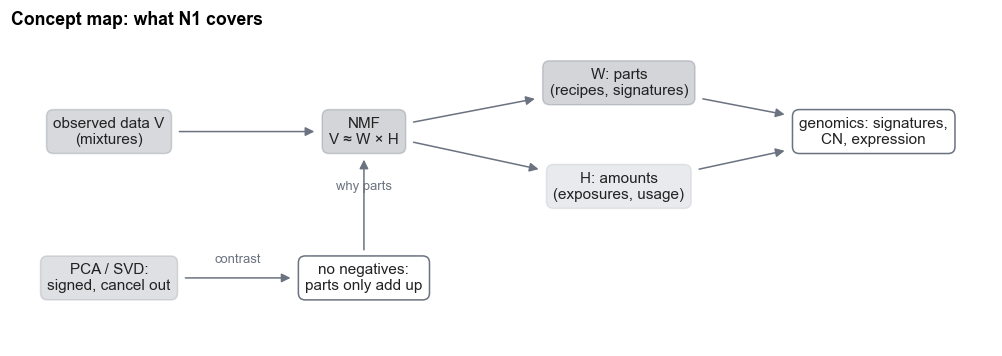

In [3]:
draw_concept_map()

**그림에서 볼 것**
- 왼쪽 위에서 시작합니다. 우리가 가진 것은 섞인 데이터 V 하나뿐입니다.
- NMF 는 V 를 W(재료)와 H(양) 두 표로 쪼갭니다.
- 아래 줄: "음수가 없다"는 조건 때문에 조각이 더해지기만 하고, 그래서 해석하기 쉬운 부품이 나옵니다. PCA 는 이 조건이 없어 조각이 서로 빼기도 합니다.
- 오른쪽: 유전체 분야에서는 W 가 signature, H 가 노출량(exposure)이나 사용량(usage)입니다.

## 먼저 알아 둘 것

### 1. 데이터 행렬: 행은 무엇, 열은 무엇

**한 줄 정의**: 데이터 행렬은 숫자를 행과 열로 늘어놓은 표입니다. 이 노트북에서는 **행 = 측정한 특징**(영양소, 변이 종류, 유전자), **열 = 표본**(컵, 종양, 세포)입니다.

**왜 필요한가**: NMF 결과를 읽을 때 자주 하는 실수는 표의 방향을 헷갈려 **W 와 H 의 이름표를 바꿔 읽는 것**입니다. NMF 자체는 V 를 넣든 전치한 Vᵀ 를 넣든 같은 문제를 풀고, W 와 H 의 역할만 서로 바뀝니다(N2 7절). scikit-learn 문서도 "NMF 문헌에서는 데이터 행렬 X 를 전치해 쓰기 때문에 이름 붙이는 방식이 보통 반대"라고 적어 둡니다 [10]. 그래서 표의 모양부터 정확히 말할 수 있어야 결과의 뜻도 정확히 읽힙니다.

**숫자로 따라가기**: 아래는 이 노트북의 장난감 데이터입니다. 과일 주스 12컵의 영양소 8가지를 쟀습니다. 행 8개 × 열 12개입니다.

In [4]:
show_matrix(dfV, "V (data)", "rows = nutrients, columns = cups")

V (data): 8 rows x 12 columns   <- rows = nutrients, columns = cups


,cup1,cup2,cup3,cup4,cup5,cup6,cup7,cup8,cup9,cup10,cup11,cup12
sugar,24.0,14.0,22.0,30.0,12.0,18.0,20.0,26.0,16.0,18.0,34.0,32.0
vitamin C,4.0,10.0,13.0,3.0,6.0,18.0,9.0,8.0,14.0,5.0,12.0,21.0
fibre,4.0,7.0,7.0,3.0,6.0,9.0,6.0,5.0,8.0,5.0,9.0,12.0
potassium,10.0,10.0,7.0,9.0,12.0,6.0,9.0,8.0,8.0,11.0,16.0,13.0
malic acid,10.0,0.0,5.0,15.0,0.0,0.0,5.0,10.0,0.0,5.0,10.0,5.0


표에서 `cup1` 열을 위에서 아래로 읽으면 "1번 컵에 sugar 24, vitamin C 4, …"입니다. 한 열이 표본 하나입니다.

> **시퀀싱 데이터에서는** mutational signature 분석의 입력이 이런 표입니다. 행은 96가지 변이 종류(치환 6종 × 앞뒤 염기 16조합), 열은 종양이고, 칸에는 그 종양에서 센 변이 개수가 들어갑니다 [6]. 개수라서 음수가 없습니다.

### 2. 행렬 곱을 "섞기"로 읽기

**한 줄 정의**: W × H 의 한 열은 W 의 열들(재료)을 H 의 그 열에 적힌 양만큼 더한 것입니다(행렬 M2 의 "열의 가중합").

**왜 필요한가**: NMF 의 식 V ≈ W × H 를 "재료를 양만큼 섞으면 데이터가 된다"로 읽는 근거가 이것입니다.

**수식 풀어 읽기**: 한 칸씩 쓰면 이렇습니다.

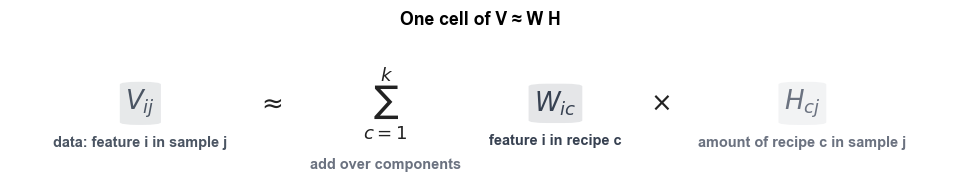

In [5]:
show_formula([(r"$V_{ij}$", COL["data"], "data: feature i in sample j"), (r"$\approx$", None, None),
              (r"$\sum_{c=1}^{k}$", None, "add over components"),
              (r"$W_{ic}$", COL["matW"], "feature i in recipe c"), (r"$\times$", None, None),
              (r"$H_{cj}$", COL["matH"], "amount of recipe c in sample j")],
             title="One cell of V ≈ W H")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $V_{ij}$ | "브이 아이 제이" | 표본 j 에서 잰 특징 i 의 값 | 아래 그림 C 의 한 칸 |
| $W_{ic}$ | "더블유 아이 씨" | 재료 c 의 조리법에 든 특징 i 의 양 | 그림 A 의 막대 하나 |
| $H_{cj}$ | "에이치 씨 제이" | 표본 j 에 넣은 재료 c 의 양 | 그림 B 의 막대 한 토막 |
| $\sum_{c=1}^{k}$ | "c 를 1 부터 k 까지 다 더한다" | 재료 k 개의 몫을 모두 더한다 | 그림 B 의 막대를 쌓기 |
| $\approx$ | "거의 같다" | 실제 데이터에는 잡음이 있어 정확히 같지는 않다 | |

**기호 사전**: k = 재료(조각, component) 개수. i 는 특징 번호, j 는 표본 번호, c 는 재료 번호입니다.

**숫자 넣기**: cup1 의 sugar = (사과 sugar 10) × (사과 2) + (당근 sugar 4) × (당근 1) + (베리 sugar 6) × (베리 0) = 20 + 4 + 0 = **24**. 위 표의 값과 같습니다.

In [6]:
assert V_SMOOTHIE[0, 0] == 10 * 2 + 4 * 1 + 6 * 0 == 24
assert np.allclose(V_SMOOTHIE, sum(np.outer(W_TRUE[:, c], H_TRUE[c]) for c in range(3)))   # 재료별 몫(rank-1 조각)의 합
print("cup1 sugar =", V_SMOOTHIE[0, 0])

cup1 sugar = 24.0


## 1. NMF 가 푸는 문제: 섞인 결과만 보고 재료와 양 찾기

**한 줄 정의**: NMF 는 음수가 없는 데이터 표 V 를, 음수가 없는 두 표 W(재료의 조리법)와 H(표본마다 넣은 양)의 곱으로 거의 같게 쪼개는 방법입니다 [1][2].

**왜 필요한가**: 우리가 보는 것은 섞인 결과(V)뿐인 경우가 많습니다. 공기 시료의 오염 물질은 여러 배출원이 섞인 것이고 [3], 종양의 변이는 여러 돌연변이 과정이 섞인 것입니다 [5]. 섞기 전의 재료와 양을 알고 싶지만 직접 볼 수 없습니다.

**숫자로 따라가기**: 주스 가게 장난감입니다. 기본 주스 3가지(사과, 당근, 베리)를 컵마다 다른 양으로 섞었습니다.

In [7]:
show_matrix(dfW, "W (recipes)", "rows = nutrients, columns = base juices")
show_matrix(dfH, "H (amounts)", "rows = base juices, columns = cups")

W (recipes): 8 rows x 3 columns   <- rows = nutrients, columns = base juices


,apple,carrot,berry
sugar,10.0,4.0,6.0
vitamin C,1.0,2.0,6.0
fibre,1.0,2.0,3.0
potassium,3.0,4.0,2.0
malic acid,5.0,0.0,0.0


H (amounts): 3 rows x 12 columns   <- rows = base juices, columns = cups


,cup1,cup2,cup3,cup4,cup5,cup6,cup7,cup8,cup9,cup10,cup11,cup12
apple,2.0,0.0,1.0,3.0,0.0,0.0,1.0,2.0,0.0,1.0,2.0,1.0
carrot,1.0,2.0,0.0,0.0,3.0,0.0,1.0,0.0,1.0,2.0,2.0,1.0
berry,0.0,1.0,2.0,0.0,0.0,3.0,1.0,1.0,2.0,0.0,1.0,3.0


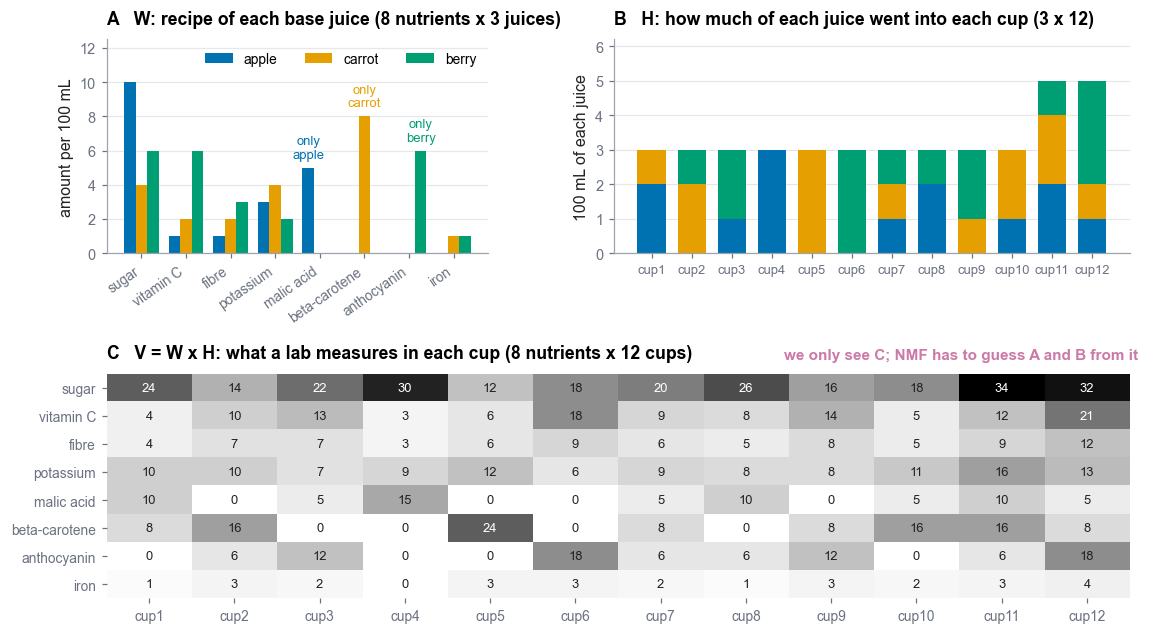

In [8]:
draw_smoothie()

**그림에서 볼 것**
- A: 기본 주스 3가지의 조리법 W 입니다. malic acid 는 사과에만, beta-carotene 은 당근에만, anthocyanin 은 베리에만 있습니다(막대 위 "only" 표시).
- B: 컵마다 넣은 양 H 입니다. 색이 같은 재료입니다(파랑 사과, 주황 당근, 초록 베리).
- C: 실험실이 실제로 재는 V 입니다. **우리가 가진 것은 C 뿐**이고, NMF 는 C 만 보고 A 와 B 를 거꾸로 찾아야 합니다.

**모양 그림**: 세 표의 모양을 실제 숫자로 그리면 이렇습니다. W 의 열 수와 H 의 행 수가 같아야(둘 다 k = 3) 곱할 수 있습니다.

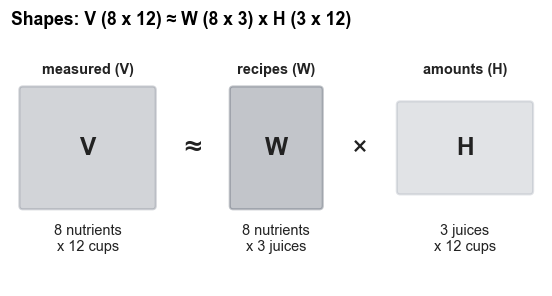

In [9]:
draw_shapes(8, 12, 3, rows="nutrients", cols="cups", comps="juices",
            captions=("measured (V)", "recipes (W)", "amounts (H)"), title="Shapes: V (8 x 12) ≈ W (8 x 3) x H (3 x 12)")

한 컵을 재료별로 나눠 쌓아 보면, 재는 값은 재료 몫을 **더하기만** 한 것입니다.

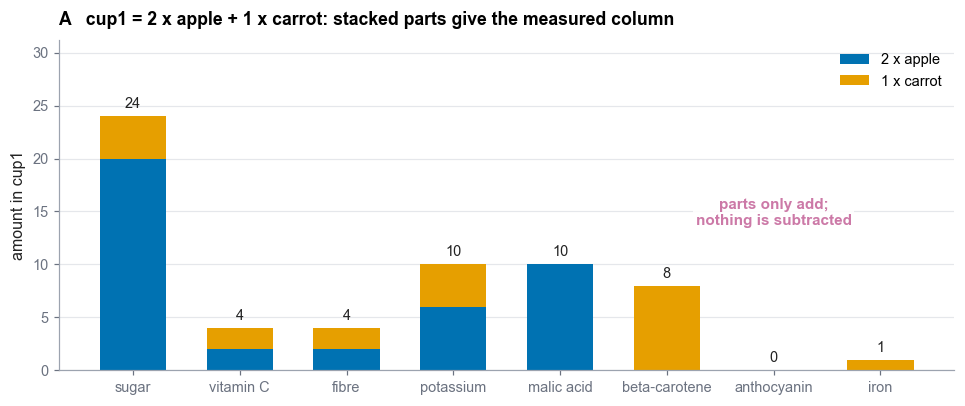

In [10]:
draw_cup_parts(0)

**그림에서 볼 것**
- cup1 은 사과 2컵 분량(파랑)과 당근 1컵 분량(주황)을 섞었습니다. 막대 위 숫자가 V 의 cup1 열입니다.
- 어느 영양소에서도 한 재료가 다른 재료의 몫을 빼지 않습니다. 이것이 "음수 없음"의 뜻입니다.

**식과 근거**: NMF 는 $V \approx WH$, $W \ge 0$, $H \ge 0$ 을 만족하는 W, H 를 찾습니다. 여기서 $\ge 0$ 은 모든 칸이 0 이상이라는 뜻입니다 [2]. Lee 와 Seung 은 이 조건 때문에 "빼기 없이 더하기만 하는(additive, not subtractive)" 조합이 되고, 그래서 부분(parts)으로 나뉜 표현이 나온다고 설명했습니다 [1].

이제 V 만 주고 NMF 를 돌려, A 와 B 를 되찾는지 봅니다. 계산 방법은 N2 에서 직접 짜 보고, 여기서는 scikit-learn 의 `NMF` 를 씁니다. scikit-learn 은 표본을 **행**에 두므로 `V.T`(컵 × 영양소)를 넣습니다(N2 의 방향 함정).

In [11]:
model = NMF(n_components=3, init="nndsvda", solver="mu", beta_loss="frobenius", max_iter=20000, tol=1e-12,
            random_state=0)
H_sk = model.fit_transform(V_SMOOTHIE.T).T        # sklearn 의 W(컵 x 3) -> 우리 H(3 x 컵)
W_sk = model.components_.T                         # sklearn 의 H(3 x 영양소) -> 우리 W(영양소 x 3)
W_hat, H_hat = normalize_W(W_sk, H_sk)
order, sims = match_columns(W_TRUE, W_hat)
W_hat, H_hat = W_hat[:, order], H_hat[order]
print("cosine to the true recipes:", np.round(sims, 4))
print("relative error ||V - WH|| / ||V|| =", round(np.linalg.norm(V_SMOOTHIE - W_hat @ H_hat) / np.linalg.norm(V_SMOOTHIE), 5))
assert sims.min() > 0.99
show_matrix(pd.DataFrame(W_hat, index=FEATURES, columns=[f"comp{c + 1}" for c in range(3)]), "W found by NMF",
            "columns scaled to sum to 1")

cosine to the true recipes: [1. 1. 1.]
relative error ||V - WH|| / ||V|| = 4e-05
W found by NMF: 8 rows x 3 columns   <- columns scaled to sum to 1


,comp1,comp2,comp3
sugar,0.50,0.19,0.25
vitamin C,0.05,0.10,0.25
fibre,0.05,0.10,0.12
potassium,0.15,0.19,0.08
malic acid,0.25,0.00,0.00


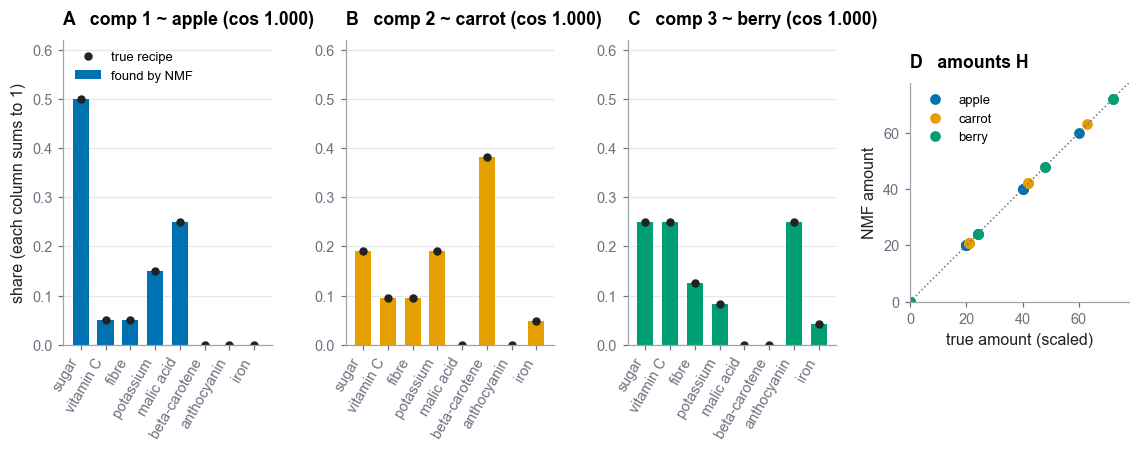

In [12]:
draw_recovery(W_hat, H_hat, sims)

**그림에서 볼 것**
- A–C: 막대는 NMF 가 찾은 재료, 검은 점은 진짜 조리법입니다. 둘 다 열의 합을 1로 맞춰 비교했습니다(크기 맞추기는 N2). 코사인 유사도(1 이면 모양이 똑같음)가 0.99 를 넘습니다.
- D: 컵마다 넣은 양도 진짜와 대각선 위에서 맞습니다.
- NMF 는 조각의 **번호를 마음대로** 붙입니다. 여기서는 진짜와 짝을 지어 순서를 맞췄습니다(N2 의 "순서 모호함").

이 장난감이 쉽게 풀린 이유는 두 가지가 함께 있었기 때문입니다. (1) W 쪽: 재료마다 **혼자만 가진 특징**(malic acid, beta-carotene, anthocyanin)이 있어 W 에 0 이 넉넉합니다. (2) H 쪽: cup4·5·6 처럼 **한 재료만 넣은 컵**이 있어 H 에도 0 이 넉넉합니다. 둘 중 하나만으로는 모자랍니다. Donoho 와 Stodden 은 답이 하나로 정해지려면 데이터가 양수 영역의 면(face)들에 걸쳐 퍼져 있어야 한다는 조건을 보였습니다 [11]. N2 5-3절에서 H 의 0(순수한 컵)을 없애면 다른 답이 생기는 것을 직접 봅니다. 잡음도 없었습니다. 이 판단은 이 노트북의 장난감에서 확인한 것입니다.

**직접 바꿔 보기**: `n_components=2` 로 바꿔 보세요. 재료 셋을 둘로 설명해야 하니 한 조각이 두 주스의 섞음이 되고 오차가 커집니다(N3 의 "k 고르기").

In [13]:
# m2 = NMF(n_components=2, init="nndsvda", solver="mu", max_iter=20000, tol=1e-12, random_state=0)
# Hx = m2.fit_transform(V_SMOOTHIE.T).T; Wx = m2.components_.T
# print(np.linalg.norm(V_SMOOTHIE - Wx @ Hx) / np.linalg.norm(V_SMOOTHIE))

## 2. 음수를 막으면 얻는 것과 잃는 것

**한 줄 정의**: "W, H 의 모든 칸이 0 이상"이라는 조건 하나가 NMF 의 장점과 단점을 함께 만듭니다.

| | 무엇 | 왜 | 어디서 더 보나 |
|---|---|---|---|
| 얻는 것 | 조각이 실제 재료처럼 읽힌다 | 더하기만 하니 각 조각이 데이터의 한 부분이 된다 [1] | 이 노트북 1·4절 |
| 얻는 것 | 양(H)을 "얼마나 섞였나"로 읽을 수 있다 | 음수 양은 뜻이 없는데, 그런 값이 나오지 않는다 | 1절 그림 D |
| 잃는 것 | 답이 하나로 정해지지 않을 수 있다 | 크기·순서·회전을 바꿔도 같은 V 를 만든다 | N2 |
| 잃는 것 | 공식으로 한 번에 풀 수 없다 | W 와 H 를 함께 보면 문제가 볼록(convex)하지 않아, 반복 계산으로 국소 최솟값을 찾는다 [2] | N2 |
| 잃는 것 | 조각 수 k 를 사람이 정해야 한다 | k 를 늘리면 가장 좋은 해의 오차는 줄거나 그대로라서, 오차만으로는 못 고른다 | N3 |

**기호 사전**: 볼록(convex) = 그릇처럼 안쪽으로 굽은 모양. 볼록하면 국소 최솟값(근처에서 가장 낮은 곳)이 곧 전체 최솟값입니다(바닥이 평평하게 넓을 수는 있습니다). 볼록하지 않으면 높이가 다른 골짜기가 여럿일 수 있어, 출발점에 따라 다른 골짜기에 닿습니다. Lee 와 Seung 은 "W 만, 또는 H 만 보면 볼록하지만 둘을 함께 보면 볼록하지 않다"고 적었습니다 [2].

## 3. PCA 와 무엇이 다른가

**한 줄 정의**: PCA(주성분 분석)도 데이터를 조각으로 나누지만, 조각끼리 직교(서로 90°)해야 하고 음수를 허용합니다(행렬 M4·M5).

**왜 필요한가**: 둘 다 "행렬 분해"라 헷갈리기 쉽습니다. Lee 와 Seung 은 PCA 가 조각을 더하고 **빼서**(cancellation) 변화를 만드는 넓게 퍼진 표현이라고 대비했습니다 [2].

**숫자로 따라가기**: 같은 주스 데이터에 PCA 를 돌립니다. PCA 는 표본을 행에 두므로 `V.T`(12컵 × 8영양소)를 넣고, 평균을 빼고 계산합니다.

In [14]:
pca = PCA(n_components=3).fit(V_SMOOTHIE.T)
pcs = pca.components_                              # 3 x 8, 부호 있음
print("explained variance:", np.round(pca.explained_variance_ratio_, 3))
print("negative entries in PCA components:", int((pcs < -1e-9).sum()), "of", pcs.size)
print("negative entries in NMF components:", int((W_hat < -1e-12).sum()), "of", W_hat.size)
assert (pcs < -1e-9).sum() > 0 and (W_hat < 0).sum() == 0
assert np.allclose(pcs @ pcs.T, np.eye(3), atol=1e-8)   # PCA 조각끼리 직교

explained variance: [0.451 0.357 0.192]
negative entries in PCA components: 11 of 24
negative entries in NMF components: 0 of 24


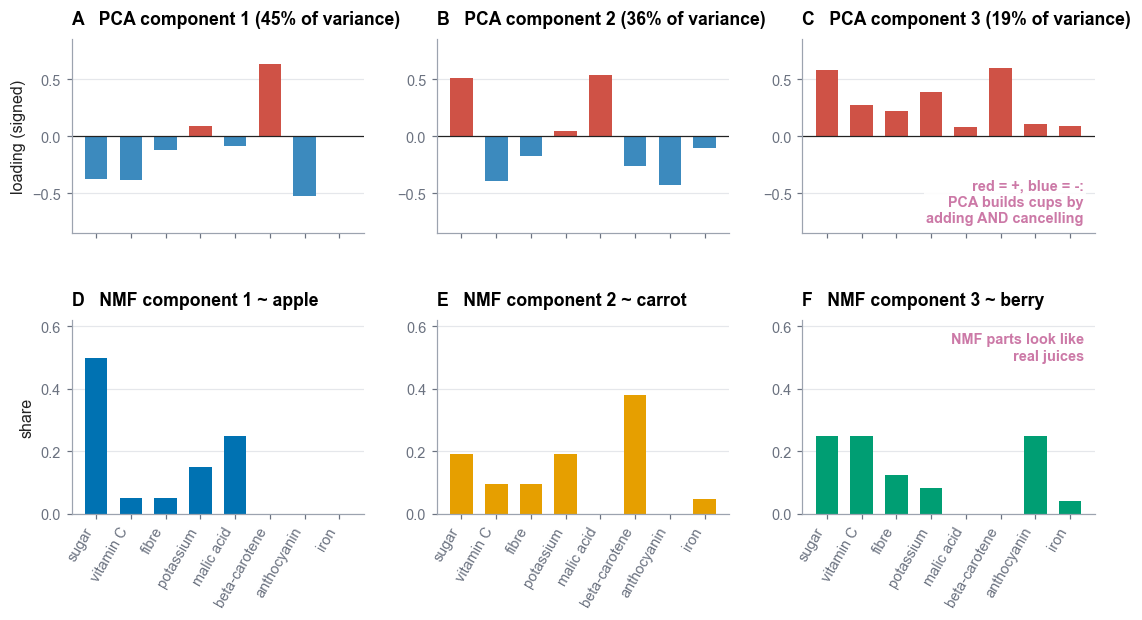

In [15]:
draw_pca_vs_nmf(pcs, pca.explained_variance_ratio_, W_hat)

**그림에서 볼 것**
- 위(A–C): PCA 조각 A 와 B 에는 빨간 막대(+)와 파란 막대(−)가 섞여 있습니다. C 는 모두 + 이지만, A·B 와 직교하도록 정해진 방향이라 역시 주스 하나의 조리법이 아닙니다. PCA 조각은 "어떤 주스"가 아니라 "평균에서 어느 쪽으로 벗어나나"를 뜻합니다.
- 아래(D–F): NMF 조각은 모두 0 이상이고, 각각 사과·당근·베리의 조리법과 닮았습니다.
- 둘 다 데이터를 잘 설명합니다. 다른 것은 **조각을 사람이 읽을 수 있느냐**입니다.

**식과 근거**: PCA 조각은 서로 직교합니다(위 assert, `pcs @ pcs.T` = 단위 행렬). 음수가 없는 두 벡터의 내적은 같은 칸에서 둘 다 0 이 아닐 때만 0 보다 커지므로, 음수 없이 직교하려면 0 이 아닌 칸이 서로 하나도 겹치지 않아야 합니다. 영양소를 나눠 갖는 주스들로는 그럴 수 없으니 PCA 조각은 음수를 가집니다. NMF 는 직교를 요구하지 않는 대신 음수를 막습니다 [1][2].

## 4. 부분을 찾는 그림: 장난감 얼굴

**한 줄 정의**: Lee 와 Seung 의 1999년 논문은 얼굴 사진에 NMF 를 돌리면 눈·코·입 같은 **부분**이 나오고, PCA 는 얼굴 전체에 걸친 무늬가 나온다는 것을 보여 줘 널리 알려졌습니다 [1].

**왜 장난감인가**: 실제 사람 얼굴 사진을 공개 저장소에 다시 싣지 않으려고, 16 × 16 칸짜리 가짜 얼굴을 만들었습니다. 얼굴 하나 = 윤곽 + 눈 둘 + 눈썹 + 코 + 웃는 입 또는 다문 입 + 볼, 이 8가지 부품을 무게를 달리해 더한 것입니다. 실제 얼굴 사진(Olivetti faces)으로 같은 비교를 하는 예는 scikit-learn 안내서에 있습니다 [10].

**숫자로 따라가기**: 그림 300장, 그림 한 장은 256 칸(16 × 16)입니다. 그림 한 장을 한 열로 펴서 늘어놓으면 V 는 256 행 × 300 열입니다.

In [16]:
V_face, W_face, H_face, PART_NAMES = make_faces()
show_matrix(pd.DataFrame(V_face[:, :6], index=[f"pixel{p}" for p in range(S * S)],
                         columns=[f"image{j + 1}" for j in range(6)]).iloc[60:66],
            "V (faces), rows 60-65 shown", f"full shape {V_face.shape[0]} pixels x {V_face.shape[1]} images")

V (faces), rows 60-65 shown: 6 rows x 6 columns   <- full shape 256 pixels x 300 images


,image1,image2,image3,image4,image5,image6
pixel60,0.79,0.01,0.53,2.00e-02,5.89e-01,8.40e-01
pixel61,1.01,1.20,0.89,1.20e+00,9.71e-01,9.80e-01
pixel62,0.02,0.01,0.03,4.30e-02,2.80e-02,6.00e-03
pixel63,0.05,0.07,0.01,3.00e-03,3.00e-03,2.00e-02
pixel64,0.05,0.02,0.00,1.20e-02,6.00e-03,3.30e-02


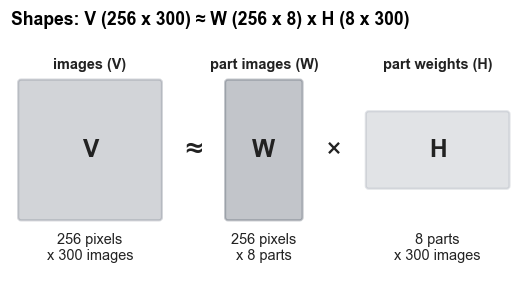

In [17]:
draw_shapes(256, 300, 8, rows="pixels", cols="images", comps="parts",
            captions=("images (V)", "part images (W)", "part weights (H)"),
            title="Shapes: V (256 x 300) ≈ W (256 x 8) x H (8 x 300)")

In [18]:
mf = NMF(n_components=8, init="nndsvda", solver="mu", max_iter=3000, tol=1e-8, random_state=0)
Hf = mf.fit_transform(V_face.T).T; Wf = mf.components_.T
Wf_n, _ = normalize_W(Wf, Hf)
order_f, sims_f = match_columns(W_face, Wf_n)
pf = PCA(n_components=8).fit(V_face.T)
print("NMF part vs true part cosine:", np.round(sims_f, 3))
assert np.median(sims_f) > 0.9

NMF part vs true part cosine: [0.995 0.93  0.926 0.937 0.935 0.93  0.937 0.995]


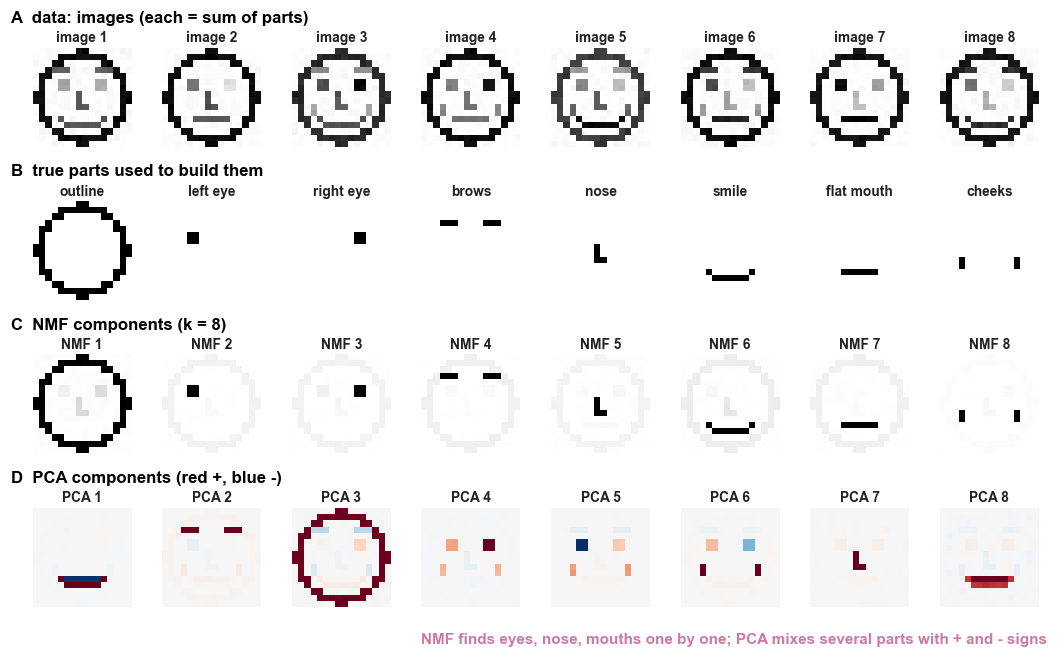

In [19]:
draw_faces(V_face, W_face, PART_NAMES, Wf_n, order_f, pf.components_.T)

**그림에서 볼 것**
- A: 데이터입니다. 눈을 감은(옅은) 얼굴, 웃는 입·다문 입이 섞여 있습니다.
- B: 그림을 만들 때 쓴 진짜 부품 8가지입니다. 우리는 이것을 모른다고 칩니다.
- C: NMF 가 V 만 보고 찾은 조각입니다(진짜와 짝을 맞춰 순서만 바꿨습니다). 눈, 코, 웃는 입, 다문 입이 따로 나옵니다.
- D: PCA 조각은 여러 부품을 한 조각에 섞고, 빨강(+)과 파랑(−)이 함께 있습니다. 예를 들어 PCA 1 은 웃는 입과 다문 입이 서로 반대 부호라 "둘 중 어느 쪽인가"를 뜻합니다. 윤곽과 눈을 한데 묶은 조각도 있습니다.

**직접 바꿔 보기**: `n_components=4` 로 줄이면 NMF 가 부품 여러 개를 한 조각에 묶습니다. 몇 개가 묶이는지 C 줄을 보세요.

## 5. 어디서 시작해서 유전체까지 왔나

**한 줄 정의**: 음수 없는 행렬 분해의 대표적인 초기 사례는 환경 과학의 PMF(1994)이고, 1999년 Lee 와 Seung 의 논문으로 널리 알려진 뒤 유전체 분석의 기본 도구가 되었습니다. 그보다 앞서 1971년 Lawton 과 Sylvestre 의 화학 스펙트럼 분해(self modeling curve resolution)도 있습니다 [12].

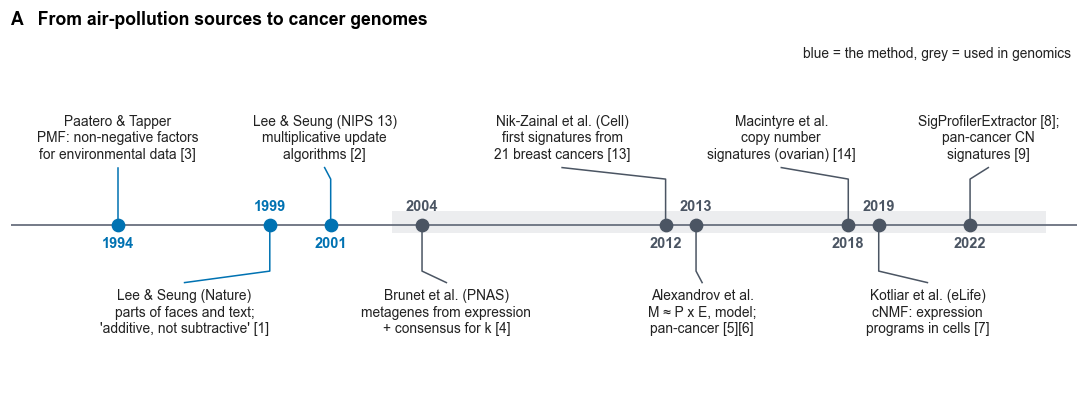

In [20]:
draw_timeline()

**그림에서 볼 것**
- 파란 점은 방법이 만들어진 단계, 회색 점(옅은 회색 띠)은 유전체 분야에서 쓰인 단계입니다.
- 1994 Paatero 와 Tapper 는 이름을 "PMF(positive matrix factorization)"라 붙였습니다. 환경 데이터에서는 값마다 오차 크기가 다르고 "음수 없음"이 모형의 본질이라, 일반 요인 분석이나 PCA 보다 낫다고 적었습니다 [3].
- 1999 Lee 와 Seung 이 "NMF"라는 이름으로 얼굴의 부분과 글의 의미 특징을 찾아 보였고 [1], 2001년 논문에서 간단한 곱셈 갱신 계산법을 냈습니다 [2].
- 2004 Brunet 등은 유전자 발현 데이터를 수천 개 유전자에서 몇 개의 "metagene"으로 줄이고, k 를 고르는 방법(consensus, N3)을 붙였습니다 [4].
- 2012 Nik-Zainal 등이 유방암 21개의 변이 표에서 처음 signature 를 뽑았고 [13], 2013 Alexandrov 등이 그 방법을 M ≈ P × E 모형으로 자세히 정리해 여러 암으로 넓혔습니다 [5][6]. Alexandrov 2013 은 스스로 "앞서 21개 유방암 유전체에서 signature 를 뽑는 방법의 첫 윤곽을 보고했다"고 적습니다 [5].
- copy number signature 는 2018 Macintyre 등의 난소암 연구가 먼저 나왔고 [14], 2022 Steele 등이 여러 암의 CN signature 를 SigProfilerExtractor 로 뽑았습니다 [9].
- 2019 Kotliar 등의 cNMF 는 단일세포 발현을 유전자 프로그램과 그 사용량으로 나눕니다 [7]. 2022 SigProfilerExtractor 가 de novo 추출 도구로 나왔습니다 [8].

**왜 유전체에서 자리 잡았나**: 변이 개수, read 개수, 발현량은 모두 0 이상인 개수이고, "여러 과정이 더해져 관측값이 된다"는 생각이 자연스럽습니다. Brunet 등은 NMF 가 계층 군집이나 SOM 보다 유전자 선택과 초기값에 덜 민감했다고 보고했습니다 [4]. 이 문장은 그 논문의 보고이고, 일반적으로 늘 그렇다는 뜻은 아닙니다.

## 6. 오늘 유전체 분야에서 쓰는 곳과 데이터 모양

| 분야 | 데이터 행렬 | 행 | 열 | W 의 뜻 | H 의 뜻 | 예 |
|---|---|---|---|---|---|---|
| mutational signature | 변이 개수 | 96가지 치환 종류 [6] | 종양 | signature(P) | 노출량(E) | Alexandrov 2013 [5], SigProfilerExtractor [8] |
| copy number signature | 구간 개수 | 48가지 CN 종류(총 CN·이형접합 여부·구간 길이) [9] | 종양 | CN signature | 노출량 | Steele 2022 [9] |
| 발현 프로그램 | 발현량 | 세포(scikit-learn 방향) | 유전자 | 사용량(usage) | 유전자 프로그램 | cNMF [7] |
| metagene | 발현량 | 유전자 | 표본 | metagene | metagene 발현 | Brunet 2004 [4] |

아래 그림은 같은 식이 분야마다 어떤 모양이 되는지 보여 줍니다. 표본 수와 k 는 예시입니다.

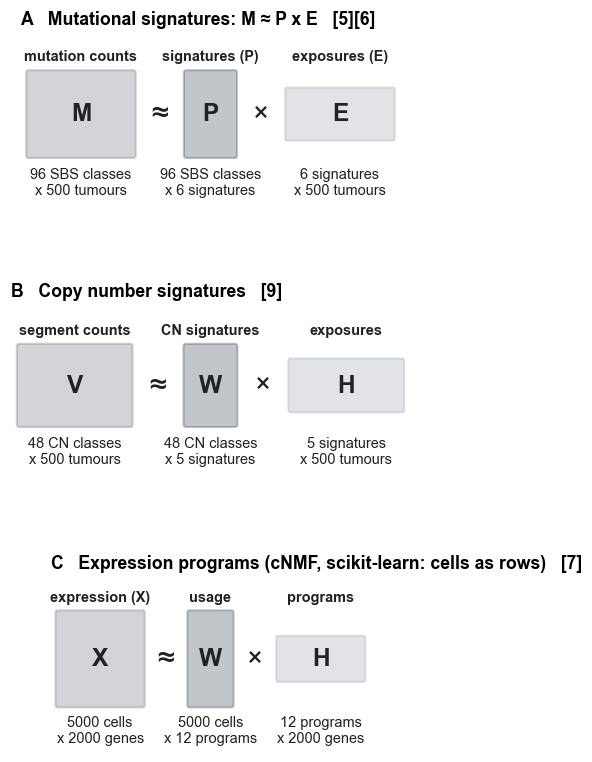

In [21]:
draw_genomics_shapes()

**그림에서 볼 것**
- 세 줄 모두 모양이 같습니다: (특징 × 표본) ≈ (특징 × k) × (k × 표본).
- 다른 것은 행의 종류(96 치환, 48 CN, 수천 유전자)와 k 의 크기입니다.
- 방향은 도구마다 다릅니다. Alexandrov 의 M ≈ P × E 에서 M 은 (변이 종류 × 종양)이고 [5], SigProfilerExtractor 도 "행은 변이 채널, 열은 표본"입니다 [8]. cNMF 는 scikit-learn 을 써서 **세포를 행**에 둡니다 [7]. 그래서 C 는 (세포 × 유전자)로 그렸습니다.

> **시퀀싱 데이터에서는** SigProfilerExtractor 는 종양 변이 표를 NMF 로 여러 번 쪼개고, 안정한 해를 골라 COSMIC 참조 signature 와 맞춥니다 [8]. Steele 등의 copy number signature 논문은 48가지 CN 표에 SigProfilerExtractor 를 기본 설정으로 쓰되, 출발점만 무작위로 바꾸고 k 마다 250번 돌렸습니다(기본은 100번) [9]. 그 과정(손실, 반복, 안정성)은 N2·N3 에서 하나씩 봅니다.

## 연습 문제

1. 사과 1, 당근 0, 베리 1 을 섞은 컵의 sugar 와 anthocyanin 은 얼마입니까?
2. 당근 조리법의 모든 숫자를 2배로 하고, 컵마다 넣은 당근 양을 절반으로 하면 V 는 바뀝니까? 이것이 NMF 결과에 주는 뜻은?
3. PCA 조각에 음수가 있는 것이 "주스의 양"으로 읽을 때 왜 문제입니까?
4. 데이터 표가 (종양 500 × 변이 종류 96) 모양으로 저장돼 있다면, Alexandrov 식 M ≈ P × E 로 쓰려면 무엇을 해야 합니까?

<details><summary>정답 보기</summary>

1. sugar = 10 + 6 = 16, anthocyanin = 0 + 6 = 6.
2. 바뀌지 않습니다. (2 × 조리법) × (½ × 양) = 조리법 × 양. 그래서 NMF 는 크기를 정하지 못하고, 보통 W 의 열 합을 1 로 맞춰 정합니다(N2).
3. 음수 양은 "주스를 뺐다"는 뜻이 되는데 그런 일은 없습니다. PCA 조각은 재료가 아니라 평균에서 벗어나는 방향입니다.
4. 전치(행과 열 바꾸기)해서 (96 × 500) 으로 만듭니다. 또는 scikit-learn 처럼 표본을 행에 두는 도구를 쓰면 W 와 H 의 뜻이 서로 바뀝니다(N2).

</details>

In [22]:
x1 = W_TRUE @ np.array([1, 0, 1])
assert x1[FEATURES.index("sugar")] == 16 and x1[FEATURES.index("anthocyanin")] == 6
W2 = W_TRUE.copy(); W2[:, 1] *= 2; H2 = H_TRUE.copy(); H2[1] /= 2
assert np.allclose(W2 @ H2, V_SMOOTHIE)
print("exercise checks passed")

exercise checks passed


## 정리

- NMF 는 음수 없는 데이터 V 를 음수 없는 W(재료)와 H(양)의 곱으로 거의 같게 쪼갭니다. 모양은 (특징 × 표본) ≈ (특징 × k) × (k × 표본) 입니다.
- 음수가 없으니 조각이 더해지기만 해서 실제 부품처럼 읽힙니다. PCA 조각은 직교하고 음수가 있어 더하고 빼며 설명합니다.
- 대가: 답이 하나가 아닐 수 있고, 반복 계산이 필요하며, k 를 사람이 정해야 합니다(N2, N3).
- 환경 과학의 PMF(1994)에서 시작해, Lee & Seung(1999, 2001)을 거쳐 metagene, mutational signature, 발현 프로그램, CN signature 로 쓰입니다.

다음 N2 에서는 NMF 계산을 처음부터 직접 짭니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Lee DD, Seung HS (1999). Learning the parts of objects by non-negative matrix factorization. *Nature* 401(6755):788–791. [doi:10.1038/44565](https://doi.org/10.1038/44565), PMID 10548103. 초록을 확인("parts of faces and semantic features of text", "only additive, not subtractive, combinations"). | 1절 근거, 4절 얼굴 예, 5절 연표 |
| [2] | Lee DD, Seung HS. Algorithms for Non-negative Matrix Factorization. *Advances in Neural Information Processing Systems 13* (NIPS 2000). [PDF](https://papers.nips.cc/paper_files/paper/2000/file/f9d1152547c0bde01830b7e8bd60024c-Paper.pdf). 1절(PCA 는 "cancellations"로 변화를 만듦), 3절(Problem 1·2, W·H 함께는 볼록하지 않음)을 확인. | 1·2·3절, 연표 |
| [3] | Paatero P, Tapper U (1994). Positive matrix factorization: A non-negative factor model with optimal utilization of error estimates of data values. *Environmetrics* 5(2):111–126. [doi:10.1002/env.3170050203](https://doi.org/10.1002/env.3170050203). Crossref 초록을 확인(X = GF + E, G·F 음수 없음, 환경 데이터에서 FA·PCA 보다 적합). | 1절, 5절 |
| [4] | Brunet J-P, Tamayo P, Golub TR, Mesirov JP (2004). Metagenes and molecular pattern discovery using matrix factorization. *PNAS* 101(12):4164–4169. [doi:10.1073/pnas.0308531101](https://doi.org/10.1073/pnas.0308531101), [PMC384712](https://pmc.ncbi.nlm.nih.gov/articles/PMC384712/). 초록과 Methods 를 확인. | 5절, 6절 표 |
| [5] | Alexandrov LB, Nik-Zainal S, Wedge DC, Campbell PJ, Stratton MR (2013). Deciphering signatures of mutational processes operative in human cancer. *Cell Reports* 3(1):246–259. [PMC3588146](https://pmc.ncbi.nlm.nih.gov/articles/PMC3588146/). "M ≈ P × E (Equation 3)"를 확인. | 5·6절 |
| [6] | Alexandrov LB 외 (2013). Signatures of mutational processes in human cancer. *Nature* 500(7463):415–421. [PMC3776390](https://pmc.ncbi.nlm.nih.gov/articles/PMC3776390/). "there are 96 possible mutations in this classification". | 먼저 알아 둘 것 1, 6절 표 |
| [7] | Kotliar D 외 (2019). Identifying gene expression programs of cell-type identity and cellular activity with single-cell RNA-Seq. *eLife* 8:e43803. [doi:10.7554/eLife.43803](https://doi.org/10.7554/eLife.43803), PMC6639075. 본문의 "usage matrix" 설명, "We use non-negative matrix factorization implemented in scikit-learn", 세포가 행인 count 행렬 C("normalization of the rows of C")를 확인. | 5·6절 |
| [8] | Islam SMA, Díaz-Gay M 외 (2022). Uncovering novel mutational signatures by de novo extraction with SigProfilerExtractor. *Cell Genomics* 2(11):100179. [doi:10.1016/j.xgen.2022.100179](https://doi.org/10.1016/j.xgen.2022.100179), PMC9646490. 결과 절의 방법 요약과 STAR Methods 의 "rows represent mutational channels while columns reflect individual cancer samples" 를 확인. | 5·6절 |
| [9] | Steele CD 외 (2022). Signatures of copy number alterations in human cancer. *Nature* 606(7916):984–991. [doi:10.1038/s41586-022-04738-6](https://doi.org/10.1038/s41586-022-04738-6), PMC9242861. "48-dimensional vector", "SigProfilerExtractor was used with default parameters, except for the initializations … random initialization", "250 NMF replicates" 를 확인. | 5·6절 |
| [10] | scikit-learn 1.4 문서. [User Guide 2.5.7 NMF](https://scikit-learn.org/1.4/modules/decomposition.html#non-negative-matrix-factorization-nmf-or-nnmf), [sklearn.decomposition.NMF](https://scikit-learn.org/1.4/modules/generated/sklearn.decomposition.NMF.html). Olivetti faces 로 NMF 와 PCA eigenfaces 를 비교한 예, `fit_transform`·`components_` 의 모양, "In the NMF literature, the naming convention is usually the opposite since the data matrix X is transposed". | 먼저 알아 둘 것 1, 1·4절 |
| [11] | Donoho D, Stodden V. When Does Non-Negative Matrix Factorization Give a Correct Decomposition into Parts? *Advances in Neural Information Processing Systems 16* (NIPS 2003). [초록 쪽](https://proceedings.neurips.cc/paper/2003/hash/1843e35d41ccf6e63273495ba42df3c1-Abstract.html). 초록("under certain conditions, basically requiring that some of the data are spread across the faces of the positive orthant, there is a unique such simplicial cone")을 확인. | 1절 |
| [12] | Lawton WH, Sylvestre EA (1971). Self Modeling Curve Resolution. *Technometrics* 13(3):617–633. [doi:10.1080/00401706.1971.10488823](https://doi.org/10.1080/00401706.1971.10488823). Crossref 서지 정보만 확인. | 5절 |
| [13] | Nik-Zainal S, Alexandrov LB, Wedge DC 외 (2012). Mutational processes molding the genomes of 21 breast cancers. *Cell* 149(5):979–993. [doi:10.1016/j.cell.2012.04.024](https://doi.org/10.1016/j.cell.2012.04.024), PMID 22608084, PMC3414841. 초록("applied mathematical methods to extract mutational signatures")을 확인. | 5절 |
| [14] | Macintyre G, Goranova TE, De Silva D 외 (2018). Copy number signatures and mutational processes in ovarian carcinoma. *Nature Genetics* 50(9):1262–1270. [doi:10.1038/s41588-018-0179-8](https://doi.org/10.1038/s41588-018-0179-8), PMID 30104763, PMC6130818. 초록("we derived copy number signatures from shallow whole-genome sequencing of 117 high-grade serous ovarian cancer cases")을 확인. | 5절 |

주스와 얼굴 데이터, 코사인 값, 오차 값은 모두 **이 노트북의 시뮬레이션 결과**입니다.